# Dependencies (py 3.12)

In [18]:
!pip install numpy
!pip install scipy
!pip install matplotlib

# Phase portrait

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.integrate import solve_ivp
from scipy.spatial import cKDTree

plt.rcParams['figure.figsize'] = [20, 20 / np.pi]

# CONSTANTS 
G = 9.81

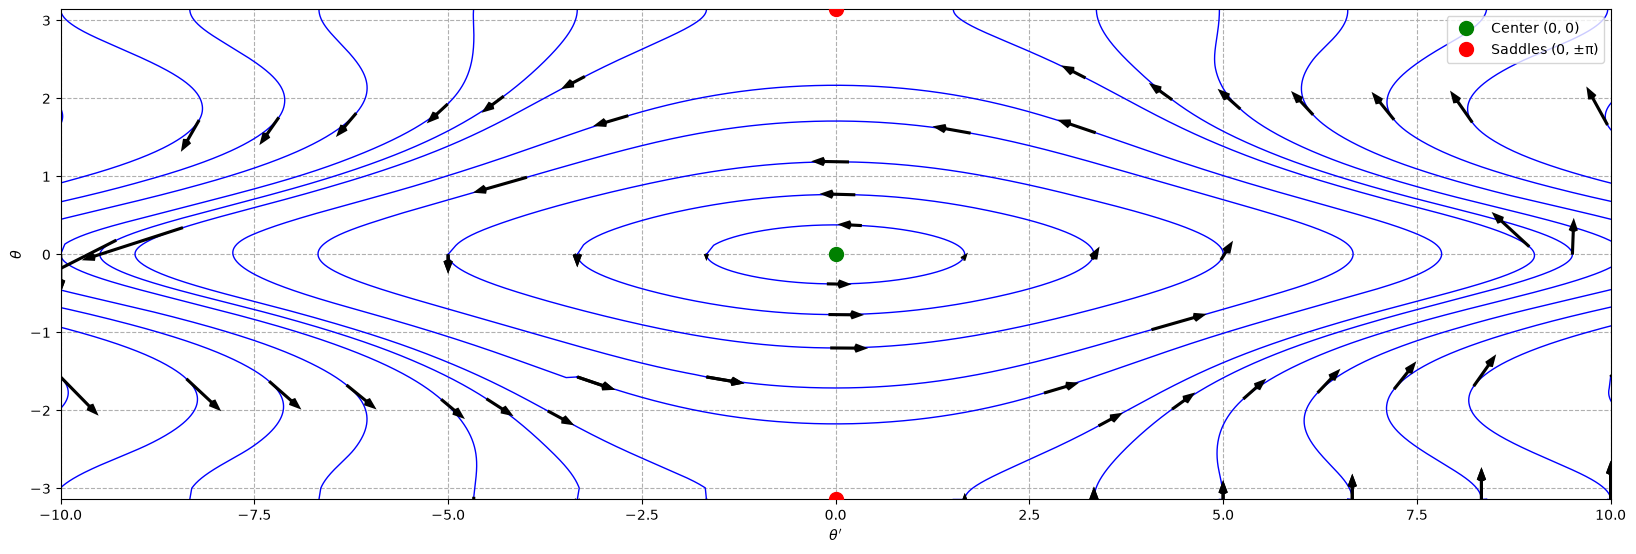

In [20]:
def get_vector(theta, omega):
    """Calculates the vector field components."""
    u = omega
    numerator = 2 * G * np.sin(theta) + np.sin(theta) * np.cos(theta) * omega ** 2
    denominator = np.cos(theta) ** 2 - 2
    v = numerator / denominator
    return u, v

def system(t, state):
    """ODE system wrapper for solve_ivp."""
    th, om = state
    u, v = get_vector(th, om)
    return [u, v]

t_eval = np.linspace(0, 10, 10000)

all_pts = []
threshold_sim = 0.1   # Minimum distance to any existing trajectory
loop_threshold = 0.15 # Distance threshold to detect closed orbits

for th0 in np.linspace(-np.pi, np.pi, 5):
    for om0 in np.linspace(-10, 10, 13):
        sol = solve_ivp(system, [0, 10], [th0, om0], t_eval=t_eval)
        
        # Wrap theta to [-pi, pi] for cylindrical phase space
        th_wrapped = (sol.y[0] + np.pi) % (2 * np.pi) - np.pi
        om = sol.y[1]
        
        # Detect closed orbits to prevent infinite overdrawing
        loop_idx = len(t_eval)
        is_loop = False 
        
        # Start checking after initial steps to allow trajectory to move away from start
        for i in range(200, len(t_eval)):
            dist_to_start = np.hypot(th_wrapped[i] - th_wrapped[0], om[i] - om[0])
            if dist_to_start < loop_threshold:
                loop_idx = i + 1 
                is_loop = True
                break
                
        # Truncate arrays if a loop is found
        th_wrapped = th_wrapped[:loop_idx]
        om = om[:loop_idx]
        
        # Force exact closure of the loop for a seamless plot
        if is_loop:
            th_wrapped = np.append(th_wrapped, th_wrapped[0])
            om = np.append(om, om[0])
        
        pts = np.column_stack((th_wrapped, om))
        
        # Skip plotting if trajectory overlaps with previously drawn ones
        if all_pts:
            tree = cKDTree(np.vstack(all_pts))
            dists, _ = tree.query(pts)
            if np.min(dists) < threshold_sim:
                continue
                
        all_pts.append(pts)
        
        # Handle wraparound jumps by inserting NaNs (prevents drawing lines across the plot)
        jumps = np.abs(np.diff(th_wrapped)) > np.pi
        split_indices = np.where(jumps)[0] + 1
        
        th_plot = np.insert(th_wrapped, split_indices, np.nan)
        om_plot = np.insert(om, split_indices, np.nan)
        
        # Draw trajectory
        plt.plot(om_plot, th_plot, color='blue', linewidth=1, zorder=2)
        
        # Add 5 direction arrows evenly spaced along the trajectory
        arrow_indices = np.linspace(0, len(th_wrapped) - 1, 5, dtype=int)
        th_pts = th_wrapped[arrow_indices]
        om_pts = om[arrow_indices]
        
        u_deriv, v_deriv = get_vector(th_pts, om_pts)
        
        plt.quiver(om_pts, th_pts, v_deriv, u_deriv, color='black', 
                   scale=400, width=0.002, headwidth=3, headlength=4, zorder=3)

# Mark equilibria
plt.plot(0, 0, 'go', markersize=10, label='Center (0, 0)', zorder=4)
plt.plot([0, 0], [-np.pi, np.pi], 'ro', markersize=10, label='Saddles (0, ±π)', zorder=4)

# Plot formatting
plt.xlim(-10, 10)
plt.ylim(-np.pi, np.pi)
plt.xlabel(r"$\theta'$")
plt.ylabel(r"$\theta$")
plt.legend(loc='upper right')
plt.grid(True, linestyle='--')

plt.show()

# Acrobot

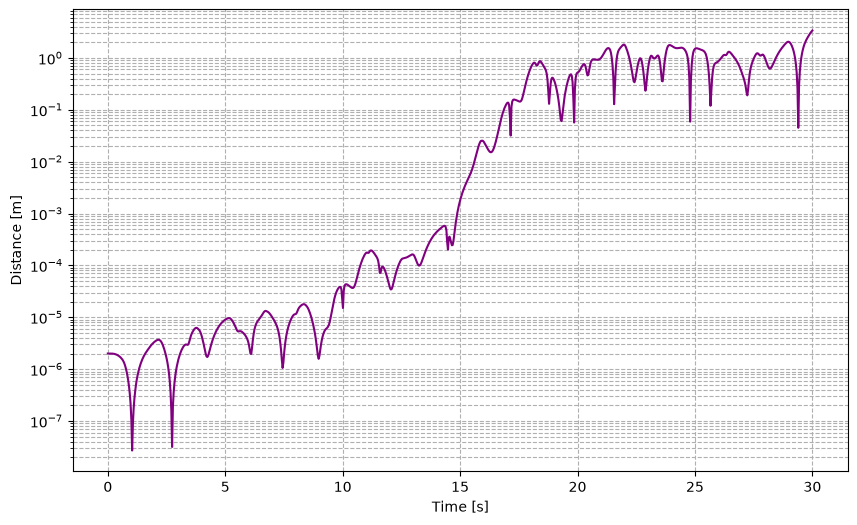

In [ ]:
def system(t, state):
    phi, theta, dphi, dtheta = state
    
    delta = 2 - np.cos(theta)**2
    
    R1 = (
        2 * np.sin(theta) * dphi * dtheta 
        + np.sin(theta) * (dtheta**2) 
        - 2 * G * np.sin(phi) 
        - G * np.sin(phi + theta)
    )
    
    R2 = (
        -np.sin(theta) * (dphi**2) 
        - G * np.sin(phi + theta)
    )
    
    ddphi = (R1 - (1 + np.cos(theta)) * R2) / delta
    ddtheta = (-(1 + np.cos(theta)) * R1 + (3 + 2 * np.cos(theta)) * R2) / delta
    
    return [dphi, dtheta, ddphi, ddtheta]


fps = 30
t_max = 30
t_eval = np.linspace(0, t_max, t_max * fps)

state_1 = [np.pi/2, 0, 0, 0]
state_2 = [np.pi/2 + 1e-6, 0, 0, 0]

sol_1 = solve_ivp(system, [0, t_max], state_1, t_eval=t_eval, rtol=1e-10, atol=1e-10)
sol_2 = solve_ivp(system, [0, t_max], state_2, t_eval=t_eval, rtol=1e-10, atol=1e-10)


# ==========================================
# PART 1: ANIMATION
# ==========================================

phi_1, theta_1 = sol_1.y[0], sol_1.y[1]
x1_1 = np.sin(phi_1)
y1_1 = -np.cos(phi_1) 
x2_1 = x1_1 + np.sin(phi_1 + theta_1)
y2_1 = y1_1 - np.cos(phi_1 + theta_1)

phi_2, theta_2 = sol_2.y[0], sol_2.y[1]
x1_2 = np.sin(phi_2)
y1_2 = -np.cos(phi_2)
x2_2 = x1_2 + np.sin(phi_2 + theta_2)
y2_2 = y1_2 - np.cos(phi_2 + theta_2)

fig_anim, ax_anim = plt.subplots(figsize=(8, 8))
ax_anim.set_xlim(-2.5, 2.5)
ax_anim.set_ylim(-2.5, 2.5)
ax_anim.set_aspect('equal')
ax_anim.grid(True, linestyle='--')

line1, = ax_anim.plot([], [], 'o-', lw=2, color='red', markersize=8, markerfacecolor='darkred', label='Acrobot 1 (Base)')
line2, = ax_anim.plot([], [], 'o-', lw=1, color='blue', markersize=6, markerfacecolor='darkblue', alpha=0.7, label='Acrobot 2 (Perturbed)')
ax_anim.legend(loc='upper left', fontsize=10)

def animate(i):
    line1.set_data([0, x1_1[i], x2_1[i]], [0, y1_1[i], y2_1[i]])
    line2.set_data([0, x1_2[i], x2_2[i]], [0, y1_2[i], y2_2[i]])
    return line1, line2

ani = animation.FuncAnimation(fig_anim, animate, frames=len(t_eval), interval=1000/fps, blit=True)
ani.save('acrobot.gif', writer='pillow', fps=fps)
plt.close(fig_anim)


# ==========================================
# PART 2: PLOT GROWTH OF DIFFERENCE
# ==========================================

distance = np.hypot(x2_1 - x2_2, y2_1 - y2_2)

fig_plot, ax_plot = plt.subplots(figsize=(10, 6))
ax_plot.semilogy(sol_1.t, distance, color='purple', linewidth=1.5)

ax_plot.set_xlabel("Time [s]")
ax_plot.set_ylabel("Distance [m]")
ax_plot.grid(True, which="both", linestyle='--')

plt.show()